# EN4554 Assignment 1, Part 1: AdaLoRA on a VLM (TextVQA vs OK-VQA)

**Paper's claim (AdaLoRA, Zhang et al. 2023):** weight matrices are not equally important, so the parameter budget should be allocated adaptively by importance. In NLP, AdaLoRA consistently gives more rank to the **top layers** and the **FFN matrices**.

**Vision-language hypothesis:** in a VLM, where AdaLoRA allocates rank depends on what the task needs from each modality:
- **TextVQA** (reading text in the image): a meaningful share of the rank goes to the **vision encoder**.
- **OK-VQA** (outside knowledge): rank concentrates in the **LM's top layers and FFNs**, as in NLP.

| Experiment | What it shows |
|---|---|
| Rank-allocation heatmaps (component × layer × module type) per task | Direct test of the claim |
| Zero-shot vs LoRA vs AdaLoRA (same budget), VQA accuracy | Baseline vs adapted |
| Bonus: LoRA with AdaLoRA's discovered allocation vs uniform (vs swapped) | Does the allocation itself matter? |

## 0. Setup

In [2]:
!pip install -q "transformers>=4.46" "peft>=0.13" datasets accelerate
# Colab's preinstalled torchao is too old for recent peft (not used here)
!pip uninstall -y -q torchao

In [3]:
import os
# Mount Drive so results, caches and model weights persist across sessions
IN_COLAB = "google.colab" in str(get_ipython()) if "get_ipython" in globals() else False
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = "/content/drive/MyDrive/EN4554_A1"
else:
    ROOT = "./outputs"
EXP       = "v2"  # results of this run go to OUT_DIR
V1_DIR    = f"{ROOT}/part1"  # first run; its zero-shot results are reused
OUT_DIR   = f"{ROOT}/part1/{EXP}"  # adapters, results, per-question scores and figures
CACHE_DIR = f"{ROOT}/cache"  # processed dataset subsets
FIG_DIR   = f"{OUT_DIR}/figures"
for d in (OUT_DIR, CACHE_DIR, FIG_DIR): os.makedirs(d, exist_ok=True)

import re, json, math, random, gc, pickle, time
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from datasets import load_dataset
from transformers import AutoProcessor, AutoModelForImageTextToText, get_cosine_schedule_with_warmup
from peft import LoraConfig, AdaLoraConfig, get_peft_model
from peft.tuners.adalora import AdaLoraLayer

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed()
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(DEVICE, torch.__version__)
T_START = time.time()

# Figure style: serif text, colour-blind-safe Okabe-Ito colours
TASK_COLOR  = {"textvqa": "#0072B2", "okvqa": "#D55E00"}  # one fixed colour per task
TASK_LABEL  = {"textvqa": "TextVQA", "okvqa": "OK-VQA"}
TOWER_LABEL = {"vision": "Vision encoder", "connector": "Connector", "text": "Language model"}
RANK_CMAP   = "Blues"  # white = pruned, dark = full rank
plt.rcParams.update({
    "font.family": "serif", "font.serif": ["DejaVu Serif"], "mathtext.fontset": "dejavuserif",
    "font.size": 8, "axes.titlesize": 8, "axes.labelsize": 8,
    "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7,
    "axes.spines.top": False, "axes.spines.right": False, "axes.linewidth": 0.6,
    "axes.grid": True, "grid.color": "#E6E6E6", "grid.linewidth": 0.5,
    "axes.prop_cycle": plt.cycler(color=["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9"]),
    "lines.linewidth": 1.5, "lines.markersize": 4,
    "figure.dpi": 120, "savefig.dpi": 300, "pdf.fonttype": 42,
})

def savefig(fig, name):
    # PDF for the report, PNG for quick viewing
    for ext in ("pdf", "png"):
        fig.savefig(f"{FIG_DIR}/{name}.{ext}", bbox_inches="tight")
    plt.show()

def elapsed():
    return f"{(time.time() - T_START) / 60:.0f} min since setup"

# Results are saved after every run, so a restarted session skips finished runs.
# Delete an entry in OUT_DIR to re-run it.
def load_json(name, default):
    path = f"{OUT_DIR}/{name}"
    return json.load(open(path)) if os.path.exists(path) else default

def save_json(obj, name):
    json.dump(obj, open(f"{OUT_DIR}/{name}", "w"), indent=1)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
cuda 2.11.0+cu130


## 1. Config

In [4]:
CFG = dict(
    model_id = "HuggingFaceTB/SmolVLM-256M-Instruct",
    tasks = {
        # (dataset id, split)
        "textvqa": dict(train=("lmms-lab-encoder/textvqa", "train"),
                        eval =("lmms-lab-encoder/textvqa", "validation")),
        # OK-VQA: "test" here is the official val2014 split
        "okvqa":   dict(train=("Multimodal-Fatima/OK-VQA_train", "train"),
                        eval =("Multimodal-Fatima/OK-VQA_test",  "test")),
    },
    n_train = 2500,
    n_eval  = 500,
    image_longest_edge = 512,  # smaller images = fewer image tokens

    # Vision encoder, connector and language model share one rank budget
    target_modules = (r".*(vision_model.*\.(q_proj|k_proj|v_proj|out_proj|fc1|fc2)"
                      r"|connector.*\.proj"
                      r"|text_model.*\.(q_proj|k_proj|v_proj|o_proj|gate_proj|up_proj|down_proj))"),

    # AdaLoRA prunes from init_r to an average of target_r (= LoRA's r, same budget)
    init_r = 12, target_r = 8, alpha = 16,
    # Pruning schedule as fractions of training: warm-up, final fixed phase, reallocation interval
    tinit_frac = 0.05, tfinal_frac = 0.35, deltaT = 5,
    beta1 = 0.85, beta2 = 0.85, orth_reg_weight = 0.5,

    lr = 5e-4, epochs = 1, batch_size = 4, grad_accum = 4,
    max_new_tokens = 16,
    eval_batch_size = 16,  # generation batch size
    num_workers = 2,  # background workers for image decoding

    bonus_swapped = False,  # bonus: also train with the other task's allocation
    reuse_v1_zero_shot = True,  # reuse zero-shot results from the first run
)

## 2. Model and processor

In [5]:
import shutil
from huggingface_hub import snapshot_download

# Keep a copy of the weights on Drive but load from local disk
# (loading through the Drive mount can corrupt safetensors files).
LOCAL_ROOT  = "/content" if IN_COLAB else ROOT
MODEL_NAME  = CFG["model_id"].split("/")[-1]
MODEL_PATH  = f"{LOCAL_ROOT}/models/{MODEL_NAME}"  # local disk
DRIVE_MODEL = f"{ROOT}/models/{MODEL_NAME}"  # persistent copy on Drive
DONE = ".copy_complete"  # marks a finished copy

if not os.path.exists(f"{MODEL_PATH}/{DONE}"):
    if os.path.exists(f"{DRIVE_MODEL}/{DONE}"):
        print("copying model from Drive -> local disk")
        shutil.copytree(DRIVE_MODEL, MODEL_PATH, dirs_exist_ok=True)
    else:
        print("downloading model from the Hub (first time only)")
        snapshot_download(CFG["model_id"], local_dir=MODEL_PATH)
        open(f"{MODEL_PATH}/{DONE}", "w").close()
        shutil.copytree(MODEL_PATH, DRIVE_MODEL, dirs_exist_ok=True, ignore=shutil.ignore_patterns(".cache"))

processor = AutoProcessor.from_pretrained(MODEL_PATH)
processor.image_processor.size = {"longest_edge": CFG["image_longest_edge"]}

def load_base_model():
    # fp32 weights; training uses fp16 autocast (the T4 has no bf16)
    return AutoModelForImageTextToText.from_pretrained(MODEL_PATH, dtype=torch.float32).to(DEVICE)

base_model = load_base_model()
print(f"params: {sum(p.numel() for p in base_model.parameters())/1e6:.1f}M")

Loading weights:   0%|          | 0/471 [00:00<?, ?it/s]

params: 256.5M


In [6]:
# Linear layers matched by target_modules, per component
def component_of(name):
    return "vision" if "vision_model" in name else "connector" if "connector" in name else "text"

matched = [n for n, m in base_model.named_modules()
           if isinstance(m, torch.nn.Linear) and re.fullmatch(CFG["target_modules"], n)]
print(Counter(component_of(n) for n in matched))
print("\n".join(matched[:3] + ["..."] + matched[-3:]))

Counter({'text': 210, 'vision': 72, 'connector': 1})
model.vision_model.encoder.layers.0.self_attn.k_proj
model.vision_model.encoder.layers.0.self_attn.v_proj
model.vision_model.encoder.layers.0.self_attn.q_proj
...
model.text_model.layers.29.mlp.gate_proj
model.text_model.layers.29.mlp.up_proj
model.text_model.layers.29.mlp.down_proj


## 3. Data

In [7]:
from io import BytesIO
from PIL import Image

# Store images as 512 px JPEG bytes to fit in Colab RAM; decode them per batch.
def shrink_image(img, longest=CFG["image_longest_edge"]):
    img = img.convert("RGB")
    img.thumbnail((longest, longest))
    buf = BytesIO(); img.save(buf, format="JPEG", quality=90)
    return buf.getvalue()

def load_image(ex):
    return Image.open(BytesIO(ex["image"])).convert("RGB")

def to_record(ex):
    answers = ex["answers"]
    if answers and isinstance(answers[0], dict):  # some datasets store answers as dicts
        answers = [a.get("answer", a.get("raw_answer")) for a in answers]
    return dict(image=shrink_image(ex["image"]), question=ex["question"], answers=answers)

def take_records(ds_id, split, n, seed=SEED):
    # convert while streaming: one full-size image in memory at a time
    ds = load_dataset(ds_id, split=split, streaming=True).shuffle(seed=seed, buffer_size=500)
    out = []
    for ex in tqdm(ds.take(n), total=n, desc=f"{ds_id} [{split}]", leave=False):
        if not out:
            print(f"  {ds_id} [{split}] fields:", {k: type(v).__name__ for k, v in ex.items()})
        out.append(to_record(ex))
    return out

DATA = {}
for task, t in CFG["tasks"].items():
    # the cache file name encodes the subset settings
    cache = f"{CACHE_DIR}/{task}_tr{CFG['n_train']}_ev{CFG['n_eval']}_px{CFG['image_longest_edge']}_s{SEED}.pkl"
    if os.path.exists(cache):
        DATA[task] = pickle.load(open(cache, "rb"))
        print(f"{task}: loaded from cache")
    else:
        DATA[task] = dict(train=take_records(*t["train"], CFG["n_train"]),
                          eval=take_records(*t["eval"], CFG["n_eval"]))
        pickle.dump(DATA[task], open(cache, "wb"))
    mb = sum(len(r["image"]) for s in DATA[task].values() for r in s) / 1e6
    print(f"{task}: train={len(DATA[task]['train'])}  eval={len(DATA[task]['eval'])}  images={mb:.0f} MB")

textvqa: loaded from cache
textvqa: train=2500  eval=500  images=155 MB
okvqa: loaded from cache
okvqa: train=2500  eval=500  images=179 MB


In [8]:
PROMPT_SUFFIX = " Answer briefly with a single word or short phrase."

def build_messages(question, answer=None):
    msgs = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": question + PROMPT_SUFFIX}]}]
    if answer is not None:
        msgs.append({"role": "assistant", "content": [{"type": "text", "text": answer}]})
    return msgs

def majority_answer(answers):
    return Counter(answers).most_common(1)[0][0]

def collate_train(batch):
    texts = [processor.apply_chat_template(build_messages(ex["question"], majority_answer(ex["answers"])),
                                           add_generation_prompt=False).strip() for ex in batch]
    enc = processor(text=texts, images=[[load_image(ex)] for ex in batch], return_tensors="pt", padding=True)
    labels = enc["input_ids"].clone()
    labels[enc["attention_mask"] == 0] = -100
    # Loss only on the answer: mask padding and everything up to 'Assistant:'
    asst = torch.tensor(processor.tokenizer("Assistant:", add_special_tokens=False).input_ids)
    k = len(asst)
    for row in range(labels.shape[0]):
        windows = enc["input_ids"][row].unfold(0, k , 1)
        starts = (windows == asst).all(dim=1).nonzero().flatten()
        if len(starts) == 0:
            raise ValueError("'Assistant:' not found:\n" + processor.tokenizer.decode(enc['input_ids'][row]))
        labels[row, :starts[-1].item() + k] = -100
    enc["labels"] = labels
    return enc

## 4. Evaluation: VQA accuracy

In [9]:
_contractions = {"dont": "don't", "doesnt": "doesn't", "isnt": "isn't", "cant": "can't", "wont": "won't"}
_articles = {"a", "an", "the"}
_num_map = {w: str(i) for i, w in enumerate(["zero","one","two","three","four","five","six","seven","eight","nine","ten"])}

def normalize_answer(s):
    s = s.lower().strip().replace("\n", " ").replace("\t", " ")
    s = re.sub(r"(?<=\d),(?=\d)", "", s)
    s = re.sub(r"[^\w\s']", " ", s)
    return " ".join(_num_map.get(w, _contractions.get(w, w)) for w in s.split() if w not in _articles)

def vqa_accuracy(pred, gt_answers):
    pred = normalize_answer(pred.split("\n")[0])
    if not pred or not gt_answers:
        return 0.0
    gts = [normalize_answer(a) for a in gt_answers]
    c = sum(g == pred for g in gts)
    return float(np.mean([min((c - (g==pred)) / 3, 1.0) for g in gts]))

@torch.no_grad()
def generate_answers(model, data, batch_size=None):
    batch_size = batch_size or CFG["eval_batch_size"]
    model.eval()
    processor.tokenizer.padding_side = "left"
    preds = []
    for i in tqdm(range(0, len(data), batch_size), leave=False):
        batch = data[i:i+batch_size]
        texts = [processor.apply_chat_template(build_messages(ex["question"]), add_generation_prompt=True) for ex in batch]
        enc = processor(text=texts, images=[[load_image(ex)] for ex in batch], return_tensors="pt", padding=True).to(DEVICE)
        with torch.autocast("cuda", dtype=torch.float16):
            out = model.generate(**enc, max_new_tokens=CFG["max_new_tokens"], do_sample=False)
        preds += [p.strip() for p in processor.batch_decode(out[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)]
    processor.tokenizer.padding_side = "right"
    return preds

def score_path(task, name):
    return f"{OUT_DIR}/scores/{task}__{re.sub(r'[^0-9A-Za-z]+', '_', name).strip('_')}.json"

def evaluate(model, task, name=""):
    data = DATA[task]["eval"]
    t0 = time.time()
    preds = generate_answers(model, data)
    scores = [vqa_accuracy(p, ex["answers"]) for p, ex in zip(preds, data)]
    # per-question scores, used by the significance test in section 11
    os.makedirs(f"{OUT_DIR}/scores", exist_ok=True)
    json.dump(dict(preds=preds, scores=scores), open(score_path(task, name), "w"))
    acc = float(np.mean(scores)) * 100
    print(f"[{task}] {name}: {acc:.2f}   (eval {(time.time() - t0) / 60:.1f} min, {elapsed()})")
    return acc

def load_scores(task, name):
    path = score_path(task, name)
    return np.array(json.load(open(path))["scores"]) if os.path.exists(path) else None

## 5. Zero-shot baseline

In [21]:
RESULTS = defaultdict(dict, load_json("results.json", {}))  # RESULTS[task][run] = accuracy
for task in CFG["tasks"]:
    if "zero-shot" in RESULTS[task]:
        print(f"[{task}] zero-shot: {RESULTS[task]['zero-shot']:.2f} (cached)")
        continue
    v1 = json.load(open(f"{V1_DIR}/results.json")) if os.path.exists(f"{V1_DIR}/results.json") else {}
    if CFG["reuse_v1_zero_shot"] and "zero-shot" in v1.get(task, {}):
        RESULTS[task]["zero-shot"] = v1[task]["zero-shot"]
        print(f"[{task}] zero-shot: {RESULTS[task]['zero-shot']:.2f} (reused from v1)")
        save_json(RESULTS, "results.json")
        continue
    RESULTS[task]["zero-shot"] = evaluate(base_model, task, "zero-shot")
    save_json(RESULTS, "results.json")

[textvqa] zero-shot: 37.34 (cached)
[okvqa] zero-shot: 36.68 (cached)


## 6. Adapters and training loop

- **LoRA**: uniform `r = target_r` on every target module.
- **AdaLoRA**: starts at `init_r`. After `tinit` warm-up steps, it prunes singular values by importance until the average rank reaches `target_r`, then freezes the allocation for the last `tfinal` steps.
- A custom loop is used because AdaLoRA needs `update_and_allocate(step)` after every optimiser step.

In [11]:
def steps_per_run(task):
    # number of optimiser steps actually taken
    n_batches = math.ceil(len(DATA[task]["train"]) / CFG["batch_size"])
    return (n_batches // CFG["grad_accum"]) * CFG["epochs"]

def build_model(kind, task, rank_pattern=None, target_modules=None):
    set_seed()
    m = load_base_model()
    tm = target_modules or CFG["target_modules"]
    if kind == "adalora":
        T = steps_per_run(task)
        cfg = AdaLoraConfig(
            init_r=CFG["init_r"], target_r=CFG["target_r"], lora_alpha=CFG["alpha"],
            tinit=int(CFG["tinit_frac"] * T), tfinal=int(CFG["tfinal_frac"] * T), deltaT=CFG["deltaT"],
            beta1=CFG["beta1"], beta2=CFG["beta2"], orth_reg_weight=CFG["orth_reg_weight"],
            total_step=T, target_modules=tm,
        )
    elif kind == "lora":
        # rank_pattern gives per-module ranks (bonus); otherwise uniform
        cfg = LoraConfig(r=CFG["target_r"], lora_alpha=CFG["alpha"], target_modules=tm,
                         rank_pattern=rank_pattern or {})
    else:
        raise ValueError(kind)
    pm = get_peft_model(m, cfg)
    pm.print_trainable_parameters()
    return pm

In [12]:
def train(pm, task, run_name, is_adalora):
    data = DATA[task]["train"]
    loader = torch.utils.data.DataLoader(data, batch_size=CFG["batch_size"], shuffle=True,
                                         collate_fn=collate_train, generator=torch.Generator().manual_seed(SEED),
                                         num_workers=CFG["num_workers"])
    t0 = time.time()
    opt = torch.optim.AdamW([p for p in pm.parameters() if p.requires_grad], lr=CFG["lr"])
    total = steps_per_run(task)
    sched = get_cosine_schedule_with_warmup(opt, int(0.03 * total), total)
    scaler = torch.amp.GradScaler("cuda")
    pm.train(); step = 0; log = []

    for epoch in range(CFG["epochs"]):
        for i, batch in enumerate(tqdm(loader, desc=f"{run_name} ep{epoch}")):
            batch = {k: v.to(DEVICE) for k, v in batch.items()}
            with torch.autocast("cuda", dtype=torch.float16):
                loss = pm(**batch).loss / CFG["grad_accum"]  # includes AdaLoRA's orthogonality regulariser
            scaler.scale(loss).backward()
            if (i + 1) % CFG["grad_accum"] != 0:
                continue
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(pm.parameters(), 1.0)
            scale_before = scaler.get_scale()
            scaler.step(opt); scaler.update()
            skipped = scaler.get_scale() < scale_before  # GradScaler skipped this step (fp16 overflow)
            if not skipped:
                sched.step()
            if is_adalora:  # only AdaLoRA reallocates rank
                if skipped:
                    # Skipped steps have inf/NaN gradients, which would make AdaLoRA's importance scores NaN
                    for p in pm.parameters():
                        if p.grad is not None:
                            p.grad.zero_()
                pm.base_model.update_and_allocate(step)  # after optimizer.step(), before zero_grad()
            opt.zero_grad(set_to_none=True)
            step += 1
            if step % 10 == 0:
                entry = dict(step=step, loss=loss.item() * CFG["grad_accum"])
                if is_adalora:
                    # current allocation from AdaLoRA's last pruning step (expected: 3396 -> 2264)
                    rp = pm.peft_config["default"].rank_pattern
                    entry["total_rank"] = sum(sum(v) for v in rp.values()) if rp else CFG["init_r"] * len(matched)
                log.append(entry)
                if is_adalora and step % 20 == 0:
                    print(entry)
    pm.save_pretrained(f"{OUT_DIR}/{run_name}")
    print(f"{run_name}: {step} steps in {(time.time() - t0) / 60:.1f} min   ({elapsed()})")
    return log

## 7. Main runs: LoRA vs AdaLoRA on each task

In [13]:
ALLOC = load_json("alloc.json", {})  # ALLOC[task] = {module: final rank}
LOGS  = load_json("logs.json", {})

def final_rank_allocation(pm, adapter="default"):
    alloc = {}
    for name, m in pm.named_modules():
        if isinstance(m, AdaLoraLayer) and adapter in m.lora_E:
            rank = int((m.lora_E[adapter] != 0).sum().item())  # singular values kept after pruning
            alloc[name.removeprefix("base_model.model.")] = rank
    return alloc

for task in CFG["tasks"]:
    for kind in ["lora", "adalora"]:
        run = f"{task}_{kind}"
        if kind in RESULTS[task] and (kind != "adalora" or task in ALLOC):
            print(f"[{task}] {kind}: {RESULTS[task][kind]:.2f} (cached, skipping)")
            continue
        pm = build_model(kind, task)
        LOGS[run] = train(pm, task, run, is_adalora=(kind == "adalora"))
        RESULTS[task][kind] = evaluate(pm, task, kind)
        if kind == "adalora":
            ALLOC[task] = final_rank_allocation(pm)
            save_json(ALLOC, "alloc.json")
        save_json(RESULTS, "results.json"); save_json(LOGS, "logs.json")
        del pm; gc.collect(); torch.cuda.empty_cache()

[textvqa] lora: 46.62 (cached, skipping)
[textvqa] adalora: 43.04 (cached, skipping)
[okvqa] lora: 42.92 (cached, skipping)


Loading weights:   0%|          | 0/471 [00:00<?, ?it/s]

trainable params: 5,812,063 || all params: 262,296,991 || trainable%: 2.2158


okvqa_adalora ep0:   0%|          | 0/625 [00:00<?, ?it/s]

{'step': 20, 'loss': 4.467956066131592, 'total_rank': 3133}
{'step': 40, 'loss': 1.5685179233551025, 'total_rank': 2661}
{'step': 60, 'loss': 0.33202868700027466, 'total_rank': 2401}
{'step': 80, 'loss': 0.7626029253005981, 'total_rank': 2289}
{'step': 100, 'loss': 2.088494300842285, 'total_rank': 2264}
{'step': 120, 'loss': 0.8037325739860535, 'total_rank': 2264}
{'step': 140, 'loss': 0.5568284392356873, 'total_rank': 2264}
okvqa_adalora: 156 steps in 9.9 min   (10 min since setup)


/usr/local/lib/python3.13/dist-packages/peft/utils/save_and_load.py:86: PeftWarning: Adapter 'default': 82 LoRA tensor(s) have invalid shape: base_model.model.model.vision_model.encoder.layers.0.self_attn.k_proj.lora_A:(0, 768), base_model.model.model.vision_model.encoder.layers.0.self_attn.k_proj.lora_B:(768, 0), base_model.model.model.vision_model.encoder.layers.0.self_attn.q_proj.lora_A:(0, 768) (+79 more). A 1-D or zero-sized lora_A / lora_B tensor indicates that DeepSpeed ZeRO-3 / FSDP shards were not gathered before save_pretrained() and are therefore incomplete. Wrap the save in deepspeed.zero.GatheredParameters([...], modifier_rank=None) for ZeRO-3, or torch.distributed.fsdp.FullyShardedDataParallel.summon_full_params(model) for FSDP, before calling save_pretrained().
  warnings.warn(


  0%|          | 0/32 [00:00<?, ?it/s]

[okvqa] adalora: 37.04   (eval 0.8 min, 11 min since setup)


## 8. Claim-tied metric: where does the rank go?

Each module is described by (component, layer index, module type). We report:
1. The share of the total rank per component (vision / connector / text), per task.
2. Attention vs FFN share within each component (the paper's FFN claim).
3. Rank against relative layer depth (the paper's top-layers claim).
4. Heatmaps of layer × module rank per component, per task.

In [14]:
ATTN = {"q_proj", "k_proj", "v_proj", "o_proj", "out_proj"}
FFN  = {"fc1", "fc2", "gate_proj", "up_proj", "down_proj"}

def describe(name):
    mod = name.split(".")[-1]
    layer = re.search(r"layers\.(\d+)\.", name)
    return dict(component=component_of(name),
                layer=int(layer.group(1)) if layer else 0,
                module=mod,
                mtype="attn" if mod in ATTN else "ffn" if mod in FFN else "proj")

def alloc_df(task):
    df = pd.DataFrame([{**describe(n), "rank": r, "name": n} for n, r in ALLOC[task].items()])
    df["depth"] = df.groupby("component")["layer"].transform(lambda x: x / max(x.max(), 1))
    return df

AL = {t: alloc_df(t) for t in ALLOC}
share = pd.DataFrame({t: d.groupby("component")["rank"].sum() / d["rank"].sum() * 100 for t, d in AL.items()}).round(1)
print("Rank share per component (%)"); display(share)
print("Attention vs FFN share within each component (%)")
display(pd.concat({t: d.groupby(["component", "mtype"])["rank"].sum()
                        .groupby(level=0).transform(lambda x: x / x.sum() * 100) for t, d in AL.items()}, axis=1).round(1))
print(f"Mean final rank per module (uniform LoRA = {CFG['target_r']})")
display(pd.concat({t: d.groupby(["component", "mtype"])["rank"].mean() for t, d in AL.items()}, axis=1).round(1))

# similarity of the two tasks' allocations
if len(AL) == 2:
    a, b = (d.set_index("name")["rank"] for d in AL.values())
    print(f"Allocation similarity TextVQA vs OK-VQA: Spearman rho = {a.corr(b, method='spearman'):.3f}, "
          f"Pearson r = {a.corr(b):.3f}, identical rank in {(a == b.reindex(a.index)).mean() * 100:.0f}% of modules")

Rank share per component (%)


,textvqa,okvqa
component,,
connector,0.5,0.5
text,77.5,75.4
vision,22.0,24.1


Attention vs FFN share within each component (%)


textvqa  okvqa
component mtype                
connector proj     100.0  100.0
text      attn      50.7   48.8
          ffn       49.3   51.2
vision    attn      49.3   50.3
          ffn       50.7   49.7

Mean final rank per module (uniform LoRA = 8)


textvqa  okvqa
component mtype                
connector proj      12.0   12.0
text      attn       7.4    6.9
          ffn        9.6    9.7
vision    attn       5.1    5.7
          ffn       10.5   11.3

Allocation similarity TextVQA vs OK-VQA: Spearman rho = 0.826, Pearson r = 0.893, identical rank in 44% of modules


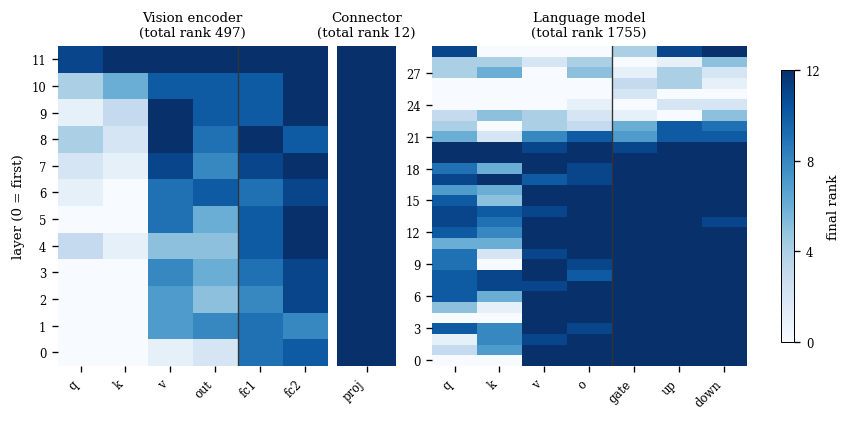

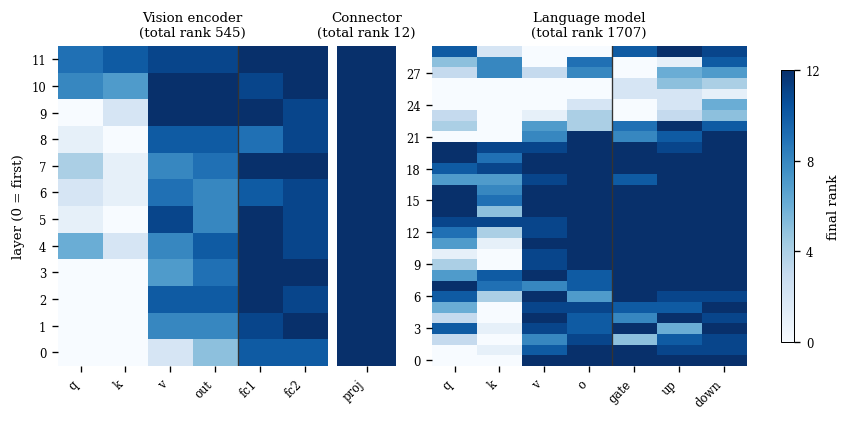

In [15]:
MOD_ORDER = {"vision":    ["q_proj", "k_proj", "v_proj", "out_proj", "fc1", "fc2"],
             "connector": ["proj"],
             "text":      ["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]}

def heatmaps(task):
    d = AL[task]
    fig, axes = plt.subplots(1, 3, figsize=(7.0, 3.4), constrained_layout=True,
                             gridspec_kw=dict(width_ratios=[6, 1.3, 7]))
    for ax, c in zip(axes, ["vision", "connector", "text"]):
        piv = d[d.component == c].pivot_table(index="layer", columns="module", values="rank", aggfunc="sum")
        piv = piv[[m for m in MOD_ORDER[c] if m in piv.columns]]
        im = ax.imshow(piv.values, aspect="auto", cmap=RANK_CMAP, vmin=0, vmax=CFG["init_r"],
                       origin="lower", interpolation="nearest")
        ax.grid(False)
        for s in ax.spines.values(): s.set_visible(False)
        ax.set_xticks(range(len(piv.columns)))
        ax.set_xticklabels([m.replace("_proj", "") for m in piv.columns], rotation=45, ha="right")
        step = 1 if len(piv.index) <= 12 else 3
        ax.set_yticks(range(0, len(piv.index), step)); ax.set_yticklabels(piv.index[::step])
        n_attn = sum(m in ATTN for m in piv.columns)  # rule between attention and FFN columns
        if 0 < n_attn < len(piv.columns):
            ax.axvline(n_attn - 0.5, color="#333333", lw=0.8)
        ax.set_title(f"{TOWER_LABEL[c]}\n(total rank {int(d[d.component == c]['rank'].sum())})")
    axes[0].set_ylabel("layer (0 = first)")
    axes[1].set_yticks([])
    fig.colorbar(im, ax=axes, shrink=0.85, label="final rank", ticks=range(0, CFG["init_r"] + 1, 4))
    savefig(fig, f"alloc_heatmap_{task}")

for t in AL: heatmaps(t)

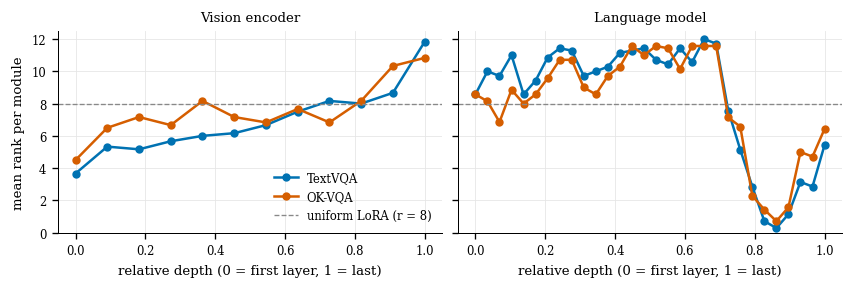

In [22]:
# Mean rank vs relative depth, per tower and task
fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.3), sharey=True, constrained_layout=True)
for ax, c in zip(axes, ["vision", "text"]):
    for t, d in AL.items():
        g = d[d.component == c].groupby("layer")["rank"].mean()
        ax.plot(g.index / g.index.max(), g.values, marker="o", color=TASK_COLOR[t], label=TASK_LABEL[t])
    ax.axhline(CFG["target_r"], color="#888888", ls="--", lw=0.8, label=f"uniform LoRA (r = {CFG['target_r']})")
    ax.set_title(TOWER_LABEL[c]); ax.set_xlabel("relative depth (0 = first layer, 1 = last)")
    ax.set_ylim(0, CFG["init_r"] + 0.5)
axes[0].set_ylabel("mean rank per module")
axes[0].legend(frameon=False, loc="lower right")
savefig(fig, "rank_vs_depth")

## 9. Baseline vs adapted

In [17]:
res = pd.DataFrame(RESULTS).round(2)
res

,textvqa,okvqa
zero-shot,37.34,36.68
lora,46.62,42.92
adalora,43.04,37.04


## 10. Bonus ablation: does the discovered allocation itself matter?

Plain LoRA (no pruning or importance scores during training) with:
- **uniform** ranks: the `lora` run from section 7;
- **discovered** ranks: AdaLoRA's final allocation for the same task;
- **swapped** ranks (optional): the other task's allocation.

**v2:** the number of trainable parameters (not just the total rank) is matched to uniform LoRA, because rank in a large FFN matrix costs more parameters than rank in a small attention matrix. If *discovered > uniform*, the allocation carries the benefit, not AdaLoRA's training procedure. "Swapped" is off by default (`CFG["bonus_swapped"]`).

> **Status:** the parameter-matched v2 bonus did not finish within our GPU budget. The report uses the rank-matched bonus from the first run (v1, results in `MyDrive/EN4554_A1/part1/bonus.json`) and labels it as exploratory.

In [18]:
# Parameter cost of one rank in each module (in + out features)
DIMS = {n: m.in_features + m.out_features for n, m in base_model.named_modules() if n in set(matched)}

def rank_pattern_from_alloc(alloc, param_budget):
    # Rescale the discovered ranks so the parameter count matches uniform LoRA
    kept = {n: r for n, r in alloc.items() if r > 0}  # LoRA can't have r=0
    scale = param_budget / sum(r * DIMS[n] for n, r in kept.items())
    ranks = {n: max(1, round(r * scale)) for n, r in kept.items()}
    print(f"  allocation -> {sum(r * DIMS[n] for n, r in ranks.items()) / 1e6:.2f}M LoRA params "
          f"(uniform: {param_budget / 1e6:.2f}M), {len(ranks)} modules")

    target_modules = list(ranks)  # exact module names
    # peft pattern keys: drop the leading "model." and escape the dots
    rank_pattern = {re.escape(n.removeprefix("model.")): r for n, r in ranks.items()}
    return target_modules, rank_pattern

BONUS = defaultdict(dict, load_json("bonus.json", {}))
tasks = list(CFG["tasks"])
param_budget = CFG["target_r"] * sum(DIMS.values())  # parameter count of uniform LoRA
for task in tasks:
    other = [t for t in tasks if t != task][0]
    variants = [("discovered", task)] + ([("swapped", other)] if CFG["bonus_swapped"] else [])
    for label, src in variants:
        if f"lora_{label}" in BONUS[task]:
            print(f"[{task}] lora[{label}]: {BONUS[task][f'lora_{label}']:.2f} (cached, skipping)")
            continue
        tm, rp = rank_pattern_from_alloc(ALLOC[src], param_budget)
        pm = build_model("lora", task, rank_pattern=rp, target_modules=tm)
        train(pm, task, f"{task}_lora_{label}", is_adalora=False)
        BONUS[task][f"lora_{label}"] = evaluate(pm, task, f"lora[{label}]")
        save_json(BONUS, "bonus.json")
        del pm; gc.collect(); torch.cuda.empty_cache()
    BONUS[task]["lora_uniform"] = RESULTS[task]["lora"]
    BONUS[task]["adalora"] = RESULTS[task]["adalora"]
save_json(BONUS, "bonus.json")
pd.DataFrame(BONUS).round(2)

  allocation -> 3.84M LoRA params (uniform: 3.87M), 246 modules


Loading weights:   0%|          | 0/471 [00:00<?, ?it/s]

trainable params: 3,839,040 || all params: 260,323,968 || trainable%: 1.4747


textvqa_lora_discovered ep0:   0%|          | 0/625 [00:00<?, ?it/s]

## 11. Significance: paired bootstrap

Each comparison uses the **same 500 eval questions**, so we resample questions (10,000 times) and look at the
accuracy difference. If the 95% CI excludes 0, the difference is unlikely to be noise from the eval sample
(it says nothing about seed-to-seed variance; we have one seed).

In [19]:
def paired_bootstrap(a, b, n_boot=10_000, seed=SEED):
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(a), size=(n_boot, len(a)))
    diffs = (b[idx] - a[idx]).mean(axis=1) * 100
    return (b.mean() - a.mean()) * 100, *np.percentile(diffs, [2.5, 97.5])

COMPARISONS = [("lora", "adalora"), ("lora", "lora[discovered]"), ("adalora", "lora[discovered]")]
rows = []
for task in CFG["tasks"]:
    for base, other in COMPARISONS:
        a, b = load_scores(task, base), load_scores(task, other)
        if a is None or b is None:
            continue
        d, lo, hi = paired_bootstrap(a, b)
        rows.append(dict(task=TASK_LABEL[task], comparison=f"{other} - {base}", diff=d, ci_low=lo, ci_high=hi,
                         significant=not (lo <= 0 <= hi)))
SIG = pd.DataFrame(rows).round(2)
SIG.to_csv(f"{OUT_DIR}/significance.csv", index=False)
SIG

,task,comparison,diff,ci_low,ci_high,significant
0,TextVQA,adalora - lora,-3.58,-6.54,-0.68,True
1,OK-VQA,adalora - lora,-5.88,-9.12,-2.72,True


## 12. Findings (final, v2 run; full write-up in `latex_report/part1.tex`)

| | TextVQA | OK-VQA |
|---|---|---|
| Zero-shot | 37.34 | 36.68 |
| LoRA r=8 | **46.62** | **42.92** |
| AdaLoRA 12→8 | 43.04 | 37.04 |
| AdaLoRA − LoRA (95% bootstrap CI) | −3.6 [−6.5, −0.7] | −5.9 [−9.1, −2.7] |

- **H1 (task–modality dependence): rejected.** The vision share is lower for TextVQA (22.0%) than for OK-VQA (24.1%), and the two allocations are strongly correlated (Spearman ρ = 0.83).
- **H2 (NLP pattern transfers): partial.** FFN > attention in both towers (vision 10.5–11.3 vs 5.1–5.7). Top > bottom layers in the vision encoder, but **reversed in the LM**, whose last ~30% of layers are pruned to almost 0. The connector keeps full rank.
- **AdaLoRA vs LoRA:** significantly worse at this short schedule, in both v1 and v2.
- **Bonus (v1, rank-matched, exploratory):** plain LoRA with the discovered allocation beats uniform (+1.5 / +1.2) and AdaLoRA itself. This is suggestive only: about 10% more parameters, and run-to-run noise is about 3 points.
- **Caveats:** single seed; 512 px images; zero-shot numbers reused from v1 (evaluated at batch 8).
